# Проект "Яндекс.Книги"
**Проверка гипотезы о среднем времени активности пользователей в разных городах**

***Примечание: Данный учебный проект выполнен в рамках программы профессиональной переподготовки.***

**Целью** данного проекта является проверка гипотезы о том, что пользователи Яндекс.Книг из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы.

**Задачи поекта**: 
1) Проверить группы на пересечение и избавиться от дубликатов в данных, если таковые имеюся;<br>
2) Проверить сопоставимость групп A и B, а именно: их размеры, распределения и статистики;
3) Обработать данные для дальнейшего анализа;<br>
4) Провести тестирование, выбрав адекватный уровень статистической значимости и подходящий вариант теста;<br>
5) Оценить результаты теста и составить аналитическую записку.

### Содержание проекта

1) Загрузка данных, описание и знакомство<br>
2) Предварительная обработка данных<br>
   - Работа с дубликатами и пересечениями в группах
   - Проверка сопоставимости групп
   - Очистка данных от выбросов
3) Проведение статистического тестирования<br>
   - Формулируем гипотезы
   - Выбираем уровень статистической значимости и вид теста
   - Проводим t-тест Уэлча
4) Аналитическая записка<br>

In [1]:
#Импорт необходимых библиотек
import pandas as pd
import statistics
import matplotlib.pyplot as plt
from scipy import stats as st

## Загрузка данных, описание и знакомство

### Описание данных
Данные предоставлены сервисом Яндекс.Книги и содержат агрегированную таблицу `yandex_knigi_data.csv` со следующими столбцами: 

`Unnamed: 0` — индекс строки;

`city` — город или регион географического положения пользователя, Москва или Санкт-Петербург;

`puid` — идентификатор пользователя;

`hours` — суммарная длительность чтения или прослушивания в часах.

### Загрузка данных и ознакомление

In [2]:
#Загружаем данные
df = pd.read_csv('datasets/yandex_knigi_data.csv') 
#Выводим 5 случайных строк для ознакомления
display(df.sample(5)) 
#Выводим количество столбцов и строк
df.shape

,Unnamed: 0,city,puid,hours
3041,3041,Москва,850190635,0.752500
7819,7819,Санкт-Петербург,1187202713,2.537891
835,835,Москва,97883304,0.572265
7006,7006,Санкт-Петербург,469236894,0.581309
822,822,Москва,94932625,1.674365


(8784, 4)

Таблица содержит 4 столбца и 8784 строки, кажадая строка содержит данные об уникальном пользователе, его регионе географического положения и суммарной длительности чтения или прослушивания в часах. Колонка `Unnamed: 0` содержит индекс строки и является артефактом сохранения таблицы. Так как среда разработки Python (pandas) при импорте файла автоматически генерирует собственную сквозную индексацию строк, колонка будет удалена.

## Предварительная обработка данных

### Работа с дубликатами и пересечениями в группах

In [3]:
#Поиск записей с одинаковым уникальным идентификатором пользователя
print(f"Количество дублириющихся идентификаторов: {(df.duplicated(subset = ['puid'])).sum()}.")
df_duplicates = df[df.duplicated(subset = ['puid'], keep = False) == True]
df_duplicates.sort_values(by = ['puid'])

Количество дублириющихся идентификаторов: 244.


,Unnamed: 0,city,puid,hours
6247,6247,Санкт-Петербург,2637041,3.883926
35,35,Москва,2637041,10.317371
134,134,Москва,9979490,32.415573
6274,6274,Санкт-Петербург,9979490,1.302997
145,145,Москва,10597984,42.931506
...,...,...,...,...
8773,8773,Санкт-Петербург,1130000020425037,2.386944
6202,6202,Москва,1130000023864516,142.830085
8775,8775,Санкт-Петербург,1130000023864516,14.384722
8779,8779,Санкт-Петербург,1130000028554332,4.107774


Можно заметить, что некоторые пользователи попали в данные обоих городов, что приводит к пересечению групп и искажению итоговых результатов тестирования. Данные таких пользователей необходимо удалить.

In [4]:
df_cleaned = df.drop_duplicates(subset = ['puid'], keep = False)
print(f"В ходе очистки было удалено {df.shape[0] - df_cleaned.shape[0]} строк, что составило \
{round((df.duplicated(subset = ['puid'])).sum()/df.shape[0]*100, 2)}% данных.")

В ходе очистки было удалено 488 строк, что составило 2.78% данных.


### Проверка сопоставимости групп 
Оценка их размеров, распределений и статистик

In [5]:
#Вычисляем размеры групп
cities = df_cleaned.groupby('city', as_index=False).agg({'puid':'count', 'hours':'sum'}).round({'hours': 2})
display(cities)

#Сопоставляем размер групп
difference_users = round(cities.iloc[0, 1]/cities.iloc[1, 1], 2)
difference_hours = round(cities.iloc[0, 2]/cities.iloc[1, 2], 2)
print(f"В Москве в {difference_users} раза больше пользователей, чем в Санкт-Петербурге, а время чтения/прослушивания в \
{difference_hours} раза дольше.")

,city,puid,hours
0,Москва,5990,64980.67
1,Санкт-Петербург,2306,25975.78


В Москве в 2.6 раза больше пользователей, чем в Санкт-Петербурге, а время чтения/прослушивания в 2.5 раза дольше.


In [6]:
#Оценим распределение количества часов чтения/прослушивания в обоих городах
stats = df_cleaned.groupby('city')['hours'].describe().T
stats

city,Москва,Санкт-Петербург
count,5990.000000,2306.000000
mean,10.848192,11.264433
std,36.925622,39.831755
min,0.000022,0.000025
25%,0.057042,0.060173
50%,0.888232,0.875355
75%,5.933439,6.138424
max,857.209373,978.764775


In [7]:
#Разделим данные о разных городах для создания визуализации
moscow_data = df_cleaned[df_cleaned['city'] == 'Москва']
spb_data = df_cleaned[df_cleaned['city'] == 'Санкт-Петербург']

# Данные для ящика с усами
data_to_plot = [moscow_data['hours'], spb_data['hours']]

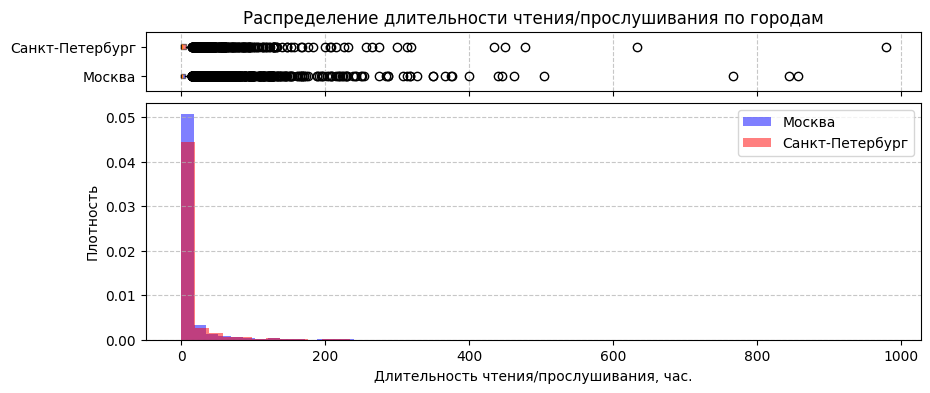

In [8]:
# Создаём 2 уровня визуализации (верхняя — ящик с усами, нижняя — гистограмма)
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, 
    figsize=(10, 4), 
    sharex=True, 
    gridspec_kw={'height_ratios': [0.2, 0.8]}
)

# 1. Верхний график (Ящики с усами)
bp = ax_box.boxplot(data_to_plot,vert=False, tick_labels=['Москва', 'Санкт-Петербург'], patch_artist=True)
# Красим ящики в те же цвета, что и гистограммы
colors = ['b', 'r']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

ax_box.set_title('Распределение длительности чтения/прослушивания по городам')
ax_box.grid(axis='x', linestyle='--', alpha=0.7)
ax_box.tick_params(axis='x', labelbottom=False)  # Скрываем подписи X сверху

# 2. Нижний график (Гистограммы)
moscow_data['hours'].plot(kind='hist', label='Москва', bins=50, alpha=0.5, color='b', density=True, ax=ax_hist)
spb_data['hours'].plot(kind='hist', label='Санкт-Петербург', bins=50, alpha=0.5, color='r', density=True, ax=ax_hist)

ax_hist.set_xlabel('Длительность чтения/прослушивания, час.')
ax_hist.set_ylabel('Плотность')
ax_hist.grid(axis='y', linestyle='--', alpha=0.7)
ax_hist.legend()

# Уменьшаем зазор между графиками
plt.subplots_adjust(hspace=0.08)

plt.show()

Тяжёлый правый "хвост" мешает оценить нормальный размах, в связи с чем создадим дополнительную визуализацию без него.

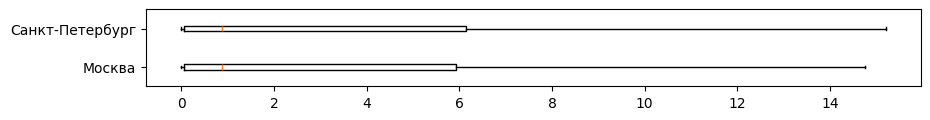

In [9]:
plt.figure(figsize=(10, 1))
bp = plt.boxplot(data_to_plot, tick_labels=['Москва', 'Санкт-Петербург'], vert = False, showfliers = False)
plt.show()

Для обоих городов характерна большая разница между медианой и средним значением (0.89 часа против 10.85 часов в Москве и 0.88 против 11.26 в Санкт-Петербурге), что говорит о сильных выбросах в области высоких значений. Стандартное отклонение высокое и практически одинаковое: 36.93 в Москве и 39.83 в Санкт-Петербурге.<br><br>
**Итого:** <br>
- Распределение в обеих группах сильно скошено вправо и имеет выбросы.
- Проведение классического t-теста может дать искажённые результаты. Необходимо избавиться от выбросов и провести t-test с поправкой Уэлча.

### Очистка данных от выбросов

In [10]:
# Посмотрим на квантили от 90% до 99.9%
quantiles = [0.90, 0.95, 0.97, 0.98, 0.99, 0.995, 0.999]

print("Москва:")
print(moscow_data['hours'].quantile(quantiles))

print("\nСанкт-Петербург:")
print(spb_data['hours'].quantile(quantiles))

Москва:
0.900     24.271757
0.950     54.929483
0.970     83.201873
0.980    112.019630
0.990    154.688119
0.995    228.838268
0.999    440.440324
Name: hours, dtype: float64

Санкт-Петербург:
0.900     28.070483
0.950     56.545642
0.970     81.399764
0.980    102.444175
0.990    146.847159
0.995    229.067649
0.999    469.177630
Name: hours, dtype: float64


До 90–95% рост активности относительно плавный (5% добавляют ~25–30 часов).С 98% до 99% рост ускоряется (со 102–112 до 146–154 часов, то есть +40 часов за 1%).<br>
После 99% происходит взрывной скачок:
- 99.0% $\rightarrow$ ~150 часов
- 99.5% $\rightarrow$ ~229 часов (+79 часов всего за 0.5%)
- 99.9% $\rightarrow$ ~440–470 часов
- Максимумы $\rightarrow$ 857–978 часов.
**Отсечём аномалии по 98-му перцентилю**, что позводит как сохранить информацию сегменте с наибольшей активностью, так и сделать метрики (среднее, std) более стабильными и упростить интерпретацию результатов статистического теста.

Удалим выбросы по 98-ому перцентилю.

In [11]:
#Находим 98-й перцентиль
cutoff_msk = moscow_data['hours'].quantile(0.98)
cutoff_spb = spb_data['hours'].quantile(0.98)
print(f'Граница отсечения выбросов для Москвы: {cutoff_msk:.2f} часа, граница для Санкт-Петербурга: {cutoff_spb:.2f} часов.')

Граница отсечения выбросов для Москвы: 112.02 часа, граница для Санкт-Петербурга: 102.44 часов.


In [12]:
#Отсекаем данные по 98-ому перцентилю
moscow_data = moscow_data[moscow_data['hours']<cutoff_msk]
spb_data = spb_data[spb_data['hours']<cutoff_spb]

## Проведение статистического тестирования

### Формулируем гипотезы
Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

### Выбираем уровень статистической значимости и вид теста
Для данного исследования был выбран стандартный для индустрии уровень статистической значимости **$\alpha$ = 0.05**. <br>
Для проверки гипотезы проведём **односторонний t-тест Уэлча**: классический тест Стьюдента может дать ложные результаты из-за наличия выбросов в выборках.

### Проводим t-тест Уэлча

In [13]:
alpha = 0.05
t_results = st.ttest_ind(moscow_data['hours'], spb_data['hours'],equal_var = False, alternative='less')
if t_results.pvalue <= alpha:
        print(f'Полученное значение p_value={round(t_results.pvalue,2)} меньше критического уровня alpha={alpha}. Принимаем альтернативную гипотезу.')
else:
        print(f'Полученное значение p_value={round(t_results.pvalue,2)} больше критического уровня alpha={alpha}.\
        Опровергнуть нулевую гипотезу нельзя.')

Полученное значение p_value=0.26 больше критического уровня alpha=0.05.        Опровергнуть нулевую гипотезу нельзя.


## Аналитическая записка

Для проверки гипотезы о том, что пользователи из Санкт-Петербурга читают или слушают книги в приложении значительно дольше пользователей из Москвы, был проведен t-тест Уэлча, использующийся для несбалансированных выборок. Выбор обоснован различием в размерах групп и отличиями в распределениях основной метрики.<br>
Результат теста **p-vale = 0.26** при уровне статистической значимости **$\alpha$ = 0.05** **не даёт основания отвергнуть нулевую гипотезу** об отсутствии статистической разницы в длительности чтения/прослушивания книг между группами. <br>

Причиной того что, несмотря на разницу в абсолютных значениях средних (средняя длительность чтения/прослушивания в Москве составила 10.85 часов, а в Санкт-Петербурге 11.26 часов), проведённое тестирование не позволило отвергнуть нулевую гипотезу может являться: 
1) **Высокая дисперсия (разброс) данных**:
Стандартное отклонение в обеих группах (около 37–40 часов) в несколько раз превышает средние значения (10.8–11.2 часа). Из-за этого колоссального разброса небольшая разница в средних значениях между городами (~25 минут) математически неотличима от случайного шума;<br>
2) **Однородность портрета пользователя**:
Москва и Санкт-Петербург — это два крупнейших мегаполиса с очень похожим стилем жизни, темпом и проникновением цифровых сервисов. Пользователи в обоих городах, скорее всего, имеют схожие привычки: слушают книги по дороге на работу/учебу в метро или во время домашних дел. Поэтому их паттерны потребления контента в приложении практически идентичны.